<a href="https://colab.research.google.com/github/govardhansnair/Black-Scholes_Options_Pricing_Model/blob/main/01_Black_Scholes_Concept.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
r=0.05
T=1
discount_factor=math.exp(-r*T)
print(discount_factor)

0.951229424500714


In [ ]:
import math
r=0.05
T=2
P=1000

A=P*math.exp(r*T)
print(A)

initial_price=100
final_price=110

log_return=math.log(final_price/initial_price)
print(log_return)

from statistics import NormalDist
N=NormalDist()

print(N.cdf(0))
print(N.cdf(1))
print(N.cdf(-1))

1105.1709180756477
0.09531017980432493
0.5
0.8413447460685429
0.15865525393145707


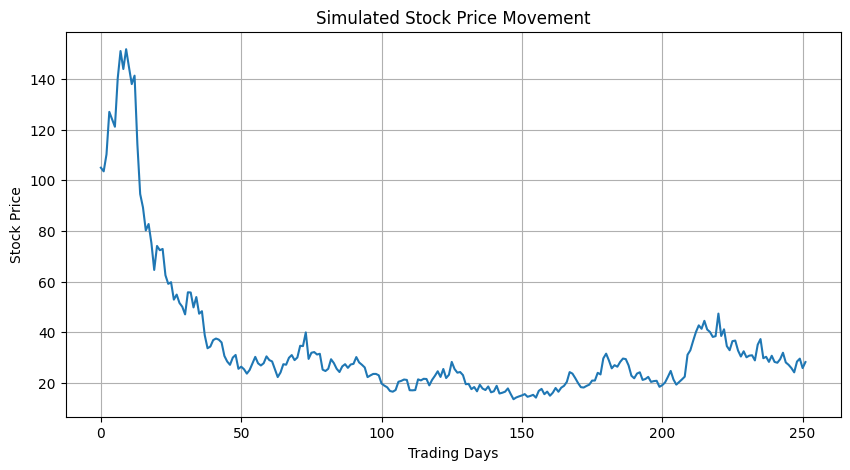

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # Ensures same random numbers are used along the entire code.
initial_price=100
daily_returns=np.random.normal(0,0.1,252)  # Generates Random daily returns for 252 days with Mean=0 and Standard Deviation=1% or 0.01
prices=initial_price*np.cumprod(1+daily_returns) # Compounds daily returns to generate sequence of stock prices.
plt.figure(figsize=(10,5))
plt.plot(prices)
plt.title("Simulated Stock Price Movement")
plt.xlabel("Trading Days")
plt.ylabel("Stock Price")

plt.grid()
plt.show()

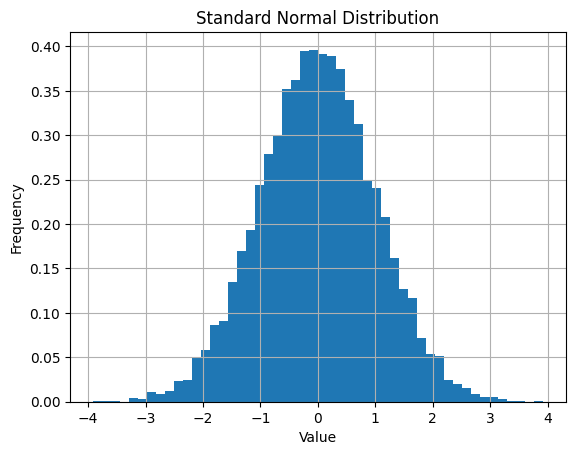

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate 10,000 random numbers
data=np.random.normal(0,1,10000)

# Plot histogram
plt.hist(data,bins=50,density=True)
plt.title("Standard Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.grid()
plt.show()

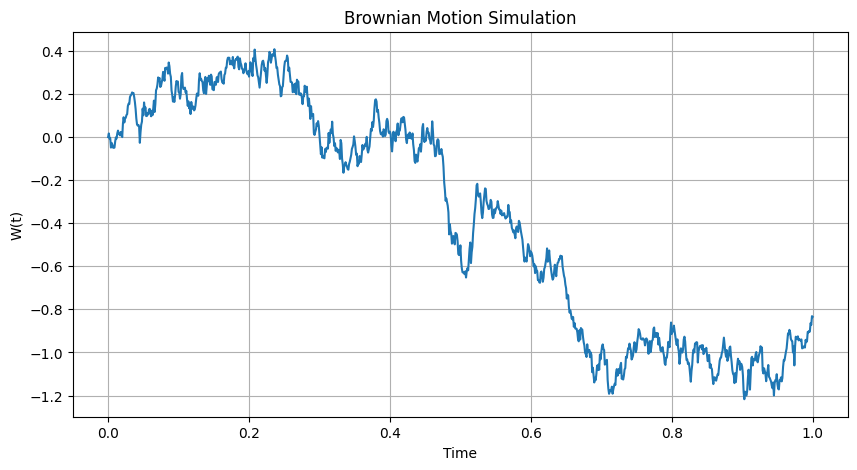

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Total Time
T=1

# Number of time intervals
N=1000

# Length of each time interval
dt=T/N

# Generate Random Movements
random_changes=np.random.normal(0,np.sqrt(dt),N)

# Start Brownian Motion at zero
W=np.zeros(N+1)        # Created an array of 1001 zeros

# Build the Brownian Motion path
for i in range(1,N+1):
  W[i]=W[i-1]+random_changes[i-1]

# Create time points
time=np.linspace(0,T,N+1)

# Plot
plt.figure(figsize=(10,5))
plt.plot(time,W)

plt.title("Brownian Motion Simulation")
plt.xlabel("Time")
plt.ylabel("W(t)")
plt.grid()
plt.show()

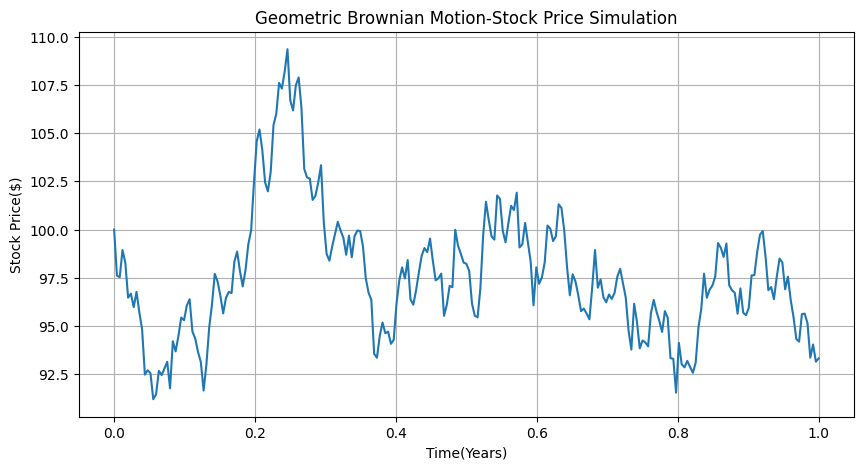

Initial Stock Price:  100
Final Stock Price:  93.31


In [ ]:
# Geometric Brownian Motion

import numpy as np
import matplotlib.pyplot as plt

# Stock parameters
s0=100
mu=0.10        # Expected return
sigma=0.20     # Volatility

# Time parameters
T=1
N=252

dt=T/N

# Generate Random Brownian Movement

random_numbers=np.random.normal(0,1,N)
dW=np.sqrt(dt)*random_numbers

# Creating an array for stock prices
S=np.zeros(N+1)
S[0]=s0

# Calculate stock prices using GBM

for i in range(1,N+1):
  S[i]=S[i-1]*np.exp((mu-0.5*sigma**2)*dt+sigma*dW[i-1])

# Creat time points
time=np.linspace(0,T,N+1)

#Plot
plt.figure(figsize=(10,5))
plt.plot(time,S)
plt.title("Geometric Brownian Motion-Stock Price Simulation")
plt.xlabel("Time(Years)")
plt.ylabel("Stock Price($)")
plt.grid()
plt.show()

print("Initial Stock Price: ",s0)
print("Final Stock Price: ",round(S[-1],2))


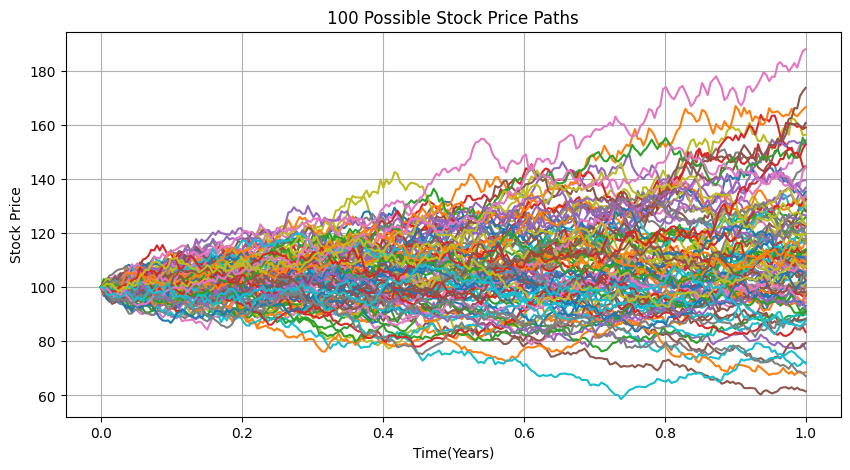

In [ ]:
# Multiple Geometric Brownian Motion

import numpy as np
import matplotlib.pyplot as plt

s0=100
mu=0.10
sigma=0.20
T=1
N=252
M=100 # Number of GBM
dt=T/N

random_numbers=np.random.normal(0,1,(N,M))
dW=np.sqrt(dt)*random_numbers
S=np.zeros((N+1,M))
S[0]=s0
for i in range(1,N+1):
  S[i]=S[i-1]*np.exp((mu-0.5*sigma**2)*dt+sigma*dW[i-1])
time=np.linspace(0,T,N+1)
plt.figure(figsize=(10,5))
plt.plot(time,S)
plt.title("100 Possible Stock Price Paths")
plt.xlabel("Time(Years)")
plt.ylabel("Stock Price")
plt.grid()
plt.show()

In [ ]:
# Mathematical Concepts used

import math
S=100
E=105
T=1
r=0.05
sigma=0.20

d1=(math.log(S/E)+(r+0.5*sigma**2)*T)/(sigma*math.sqrt(T))

d2=d1-sigma*math.sqrt(T)

# Calculate standard Normal Cumulative Distribution----> N(d1) and N(d2)
from scipy.stats import norm
N_d1=norm.cdf(d1)                                                   # norm.cdf() calculates the area area under the standard normal curve to the left of the given value.
N_d2=norm.cdf(d2)

# For put input
N_minus_d1=norm.cdf(-d1)
N_minus_d2=norm.cdf(-d2)


# Discount Strike taking into consideration contiuosly compounded risk-free rate
discount_strike=E*math.exp(-r*T)

# Call option price
first_part=S*N_d1
second_part=discount_strike*N_d2
C=first_part-second_part

# Put option price
first_part=discount_strike*N_minus_d2
second_part=S*N_minus_d1

P=first_part-second_part

print(d1)
print(d2)
print(N_d1)
print(N_d2)
print(C)
print(P)

0.10604917915283975
-0.09395082084716026
0.5422283335848053
0.46257411156882894
8.021352235143176
7.9004418077181455


In [ ]:
from functools import partialmethod
# Cumulative distribution function
from scipy.stats import norm
def N(x):
  return norm.cdf(x)

# Probability Density Function
def phi(x):
  return norm.pdf(x)

d1=(np.log(S/E)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))

d2=d1-sigma*np.sqrt(T)

# European Call Option
call=(S*np.exp(-q*T)*N(d1)-K*np.exp(-r*T)*N(d2))

# European Put Option
put=(K*np.exp(-r*T)*N(-d2)-S*np.exp(-q*T)*N(-d1))

# GREEKS
# Delta - Sensitivity to underlying price
call_delta=np.exp(-q*T)*N(d1)
put_delta=np.exp(-q*T)*(N(d1)-1)

# Gamma - Sensitivity of Delta
gamma=np.exp(-q*T)*phi(d1)/(S*sigma*np.sqrt(T))

# Theta - Sensitivity to time
common_theta=(-S*np.exp(-q*T)*phi(d1)*sigma/(2*np.sqrt(T)))
call_theta=(common_theta-r*K*np.exp(-r*T)*N(d2)+q*S*np.exp(-q*T)*N(d1))
put_theta=(common_theta+r*K*np.exp(-r*T)*N(-d2)-q*S*np.exp(-q*T)*N(-d1))

# Vega - Sensitivity to volatility
vega=(S*np.exp(-q*T)*phi(d1)*np.sqrt(T))
vega_per_point=vega/100

# Rho - Sensitivity to interest rates
 call_rho=K*T*np.exp(-r*T)*N(d2)
 put_rho=-K*T*np.exp(-r*T)*N(-d2)

call_rho_per_point=call_rho/100
put_rho_per_point=put_rho/100

# Binary Options
binary_call=np.exp(-r*T)*N(d2)
binary_put=np.exp(-r*T)*N(-d2)

# Put-Call parity
parity_lhs=call-put
parity_rhs=(S*np.exp(-q*T)-K*np.exp(-r*T))
difference=parity_lhs-parity_rhs

# Intrinsic Value
call_intrinsic=max(S-K,0)
put_intrinsic=max(K-s,0)

# Time Value
call_time_value=call-call_intrinsic
put_time_value=put-put_intrinsic

